In [12]:
import numpy as np
import pandas as pd
import wandb
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

wandb.login()

True

In [13]:
data = pd.read_csv('../data/raw/cs-training.csv', index_col=0)

TARGET_COL = 'SeriousDlqin2yrs'
X = data.drop(columns=[TARGET_COL])
y = data[TARGET_COL]

print(f"Размер матрицы признаков X: {X.shape}")
print(f"Размер вектора целевой переменной y: {y.shape}")

Размер матрицы признаков X: (150000, 10)
Размер вектора целевой переменной y: (150000,)


# Эксперимент 1: Наивный baseline (Logistic Regression)

Фиксируем отправную точку качества модели на сырых данных без специфичной очистки и генерации признаков.

Пайплайн включает базовые стандартные шаги:

* Заполнение всех пропущенных значений медианой обучающей выборки (`SimpleImputer`).
* Масштабирование признаков до нулевого среднего и единичной дисперсии (`StandardScaler`).
* Обучение логистической регрессии со сбалансированными весами классов (`class_weight='balanced'`) для компенсации дисбаланса 93.3% / 6.7%.
* Оценка качества на 5-фолдовой стратифицированной кросс-валидации (`StratifiedKFold`).

In [14]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pipe_naive = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

oof_preds_naive = np.zeros(len(X))
fold_roc_aucs = []
fold_pr_aucs = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
    X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]

    pipe_naive.fit(X_train, y_train)
    val_preds = pipe_naive.predict_proba(X_val)[:, 1]

    oof_preds_naive[val_idx] = val_preds

    fold_roc = roc_auc_score(y_val, val_preds)
    fold_pr = average_precision_score(y_val, val_preds)

    fold_roc_aucs.append(fold_roc)
    fold_pr_aucs.append(fold_pr)
    print(f"Fold {fold + 1} | ROC-AUC: {fold_roc:.4f} | PR-AUC: {fold_pr:.4f}")

mean_roc_auc = float(np.mean(fold_roc_aucs))
std_roc_auc = float(np.std(fold_roc_aucs))
mean_pr_auc = float(np.mean(fold_pr_aucs))
std_pr_auc = float(np.std(fold_pr_aucs))
oof_roc_auc = float(roc_auc_score(y, oof_preds_naive))
oof_pr_auc = float(average_precision_score(y, oof_preds_naive))

print(f"\nMean ROC-AUC: {mean_roc_auc:.4f} ± {std_roc_auc:.4f}")
print(f"Mean PR-AUC:  {mean_pr_auc:.4f} ± {std_pr_auc:.4f}")
print(f"OOF ROC-AUC:  {oof_roc_auc:.4f}")
print(f"OOF PR-AUC:   {oof_pr_auc:.4f}")

run = wandb.init(
    project="credit-scoring",
    name="01_baseline_naive_lr",
    config={
        "stage": "baseline",
        "model_type": "LogisticRegression",
        "pipeline": "naive",
        "preprocessing": "median_imputer + standard_scaler",
        "class_weight": "balanced",
        "cv_type": "StratifiedKFold",
        "cv_splits": 5,
        "random_state": 42,
        "n_features": X.shape[1]
    }
)

wandb.log({
    "cv_roc_auc_mean": mean_roc_auc,
    "cv_roc_auc_std": std_roc_auc,
    "cv_pr_auc_mean": mean_pr_auc,
    "cv_pr_auc_std": std_pr_auc,
    "oof_roc_auc": oof_roc_auc,
    "oof_pr_auc": oof_pr_auc
})

wandb.finish()

Fold 1 | ROC-AUC: 0.7888 | PR-AUC: 0.3003
Fold 2 | ROC-AUC: 0.7950 | PR-AUC: 0.2990
Fold 3 | ROC-AUC: 0.7876 | PR-AUC: 0.3119
Fold 4 | ROC-AUC: 0.7859 | PR-AUC: 0.3046
Fold 5 | ROC-AUC: 0.7953 | PR-AUC: 0.3184

Mean ROC-AUC: 0.7905 ± 0.0039
Mean PR-AUC:  0.3068 ± 0.0073
OOF ROC-AUC:  0.7905
OOF PR-AUC:   0.3067


cv_pr_auc_mean,▁
cv_pr_auc_std,▁
cv_roc_auc_mean,▁
cv_roc_auc_std,▁
oof_pr_auc,▁
oof_roc_auc,▁
cv_pr_auc_mean,0.30685
cv_pr_auc_std,0.00733
cv_roc_auc_mean,0.79053
cv_roc_auc_std,0.00388
oof_pr_auc,0.30665


1. **Метрики валидации:**
   * **Mean ROC-AUC:** 0.7905 ± 0.0039 (OOF ROC-AUC: 0.7905)
   * **Mean PR-AUC:** 0.3068 ± 0.0073 (OOF PR-AUC: 0.3067)
   * Низкое стандартное отклонение между фолдами (± 0.0039) подтверждает стабильность 5-фолдовой стратифицированной схемы валидации.

2. **Интерпретация:**
   * Базовый уровень ROC-AUC ~0.79 получен без специальной очистки и генерации признаков.
   * Уровень PR-AUC ~0.307 существенно выше случайного угадывания.
   * Текущая модель обучается с шумом: веса искажаются кодами 96/98 в просрочках и выбросами в `RevolvingUtilization` и `DebtRatio`.

# Эксперимент 2: Baseline с предобработкой по выводам EDA

Проверяем влияние очистки данных на ту же самую модель с идентичными гиперпараметрами и схемой разбиения.

В пайплайн добавляется кастомный трансформер EDAPreprocessor, который:
* Заменяет некорректный возраст (age <= 0) на медиану обучающей выборки и ограничивает его до 100 лет.
* Создает бинарный флаг has_past_due_anomaly для кодов 96/98 и зануляет эти значения в исходных признаках просрочек.
* Добавляет бинарный индикатор пропуска дохода MonthlyIncome_is_missing.
* Клиппирует экстремальные значения в RevolvingUtilizationOfUnsecuredLines (до 3.0) и DebtRatio (до 10 000.0).

In [15]:
from sklearn.base import BaseEstimator, TransformerMixin

class EDAPreprocessor(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X, y=None):
        X_df = X.copy()
        valid_ages = X_df.loc[X_df['age'] > 0, 'age']
        self.age_median_ = float(valid_ages.median()) if len(valid_ages) > 0 else 52.0
        return self

    def transform(self, X):
        X_df = X.copy()

        X_df.loc[X_df['age'] <= 0, 'age'] = self.age_median_
        X_df['age'] = X_df['age'].clip(upper=100.0)

        due_cols = [
            'NumberOfTime30-59DaysPastDueNotWorse',
            'NumberOfTime60-89DaysPastDueNotWorse',
            'NumberOfTimes90DaysLate'
        ]
        X_df['has_past_due_anomaly'] = (X_df[due_cols] >= 96).any(axis=1).astype(int)
        for col in due_cols:
            X_df.loc[X_df[col] >= 96, col] = 0

        X_df['MonthlyIncome_is_missing'] = X_df['MonthlyIncome'].isna().astype(int)

        X_df['RevolvingUtilizationOfUnsecuredLines'] = X_df['RevolvingUtilizationOfUnsecuredLines'].clip(upper=3.0)
        X_df['DebtRatio'] = X_df['DebtRatio'].clip(upper=10000.0)

        return X_df

pipe_clean = Pipeline([
    ('eda_preproc', EDAPreprocessor()),
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

oof_preds_clean = np.zeros(len(X))
fold_roc_aucs_clean = []
fold_pr_aucs_clean = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
    X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]

    pipe_clean.fit(X_train, y_train)
    val_preds = pipe_clean.predict_proba(X_val)[:, 1]

    oof_preds_clean[val_idx] = val_preds

    fold_roc = roc_auc_score(y_val, val_preds)
    fold_pr = average_precision_score(y_val, val_preds)

    fold_roc_aucs_clean.append(fold_roc)
    fold_pr_aucs_clean.append(fold_pr)
    print(f"Fold {fold + 1} | ROC-AUC: {fold_roc:.4f} | PR-AUC: {fold_pr:.4f}")

mean_roc_auc_clean = float(np.mean(fold_roc_aucs_clean))
std_roc_auc_clean = float(np.std(fold_roc_aucs_clean))
mean_pr_auc_clean = float(np.mean(fold_pr_aucs_clean))
std_pr_auc_clean = float(np.std(fold_pr_aucs_clean))
oof_roc_auc_clean = float(roc_auc_score(y, oof_preds_clean))
oof_pr_auc_clean = float(average_precision_score(y, oof_preds_clean))

diff_roc = mean_roc_auc_clean - mean_roc_auc
diff_pr = mean_pr_auc_clean - mean_pr_auc

print(f"\nMean ROC-AUC (Cleaned): {mean_roc_auc_clean:.4f} ± {std_roc_auc_clean:.4f} (прирост: {diff_roc:+.4f})")
print(f"Mean PR-AUC  (Cleaned): {mean_pr_auc_clean:.4f} ± {std_pr_auc_clean:.4f} (прирост: {diff_pr:+.4f})")
print(f"OOF ROC-AUC  (Cleaned): {oof_roc_auc_clean:.4f}")
print(f"OOF PR-AUC   (Cleaned): {oof_pr_auc_clean:.4f}")

run = wandb.init(
    project="credit-scoring",
    name="02_baseline_cleaned_lr",
    config={
        "stage": "baseline",
        "model_type": "LogisticRegression",
        "pipeline": "eda_cleaned",
        "preprocessing": "eda_rules + median_imputer + standard_scaler",
        "class_weight": "balanced",
        "cv_type": "StratifiedKFold",
        "cv_splits": 5,
        "random_state": 42,
        "n_features": X.shape[1] + 2
    }
)

wandb.log({
    "cv_roc_auc_mean": mean_roc_auc_clean,
    "cv_roc_auc_std": std_roc_auc_clean,
    "cv_pr_auc_mean": mean_pr_auc_clean,
    "cv_pr_auc_std": std_pr_auc_clean,
    "oof_roc_auc": oof_roc_auc_clean,
    "oof_pr_auc": oof_pr_auc_clean,
    "diff_roc_auc": diff_roc,
    "diff_pr_auc": diff_pr
})

wandb.finish()

Fold 1 | ROC-AUC: 0.8536 | PR-AUC: 0.3640
Fold 2 | ROC-AUC: 0.8555 | PR-AUC: 0.3724
Fold 3 | ROC-AUC: 0.8622 | PR-AUC: 0.3905
Fold 4 | ROC-AUC: 0.8479 | PR-AUC: 0.3610
Fold 5 | ROC-AUC: 0.8592 | PR-AUC: 0.3838

Mean ROC-AUC (Cleaned): 0.8557 ± 0.0049 (прирост: +0.0651)
Mean PR-AUC  (Cleaned): 0.3743 ± 0.0113 (прирост: +0.0675)
OOF ROC-AUC  (Cleaned): 0.8556
OOF PR-AUC   (Cleaned): 0.3734


cv_pr_auc_mean,▁
cv_pr_auc_std,▁
cv_roc_auc_mean,▁
cv_roc_auc_std,▁
diff_pr_auc,▁
diff_roc_auc,▁
oof_pr_auc,▁
oof_roc_auc,▁
cv_pr_auc_mean,0.37435
cv_pr_auc_std,0.01128
cv_roc_auc_mean,0.85566


In [16]:
oof_df = pd.DataFrame({
    'index': data.index,
    'true_target': y.values,
    'pred_prob_naive': oof_preds_naive,
    'pred_prob_cleaned': oof_preds_clean
})

oof_df.to_csv('../data/processed/oof_predictions_baseline.csv', index=False)
print("OOF-предсказания успешно сохранены в data/processed/oof_predictions_baseline.csv")

OOF-предсказания успешно сохранены в data/processed/oof_predictions_baseline.csv


1. **Динамика метрик:**
   * **Mean ROC-AUC:** 0.8557 ± 0.0049 (прирост **+0.0651** относительно наивного baseline 0.7905).
   * **Mean PR-AUC:** 0.3743 ± 0.0113 (прирост **+0.0675** относительно наивного baseline 0.3068).
   * **OOF ROC-AUC:** 0.8556.

2. **Причины прироста качества:**
   * Изоляция технических спецкодов 96 и 98 в отдельный бинарный флаг `has_past_due_anomaly` и зануление их в исходных колонках сняло сильнейшее искажение весов в признаках прошлых просрочек.
   * Клиппинг экстремальных выбросов в `RevolvingUtilizationOfUnsecuredLines` (до 3.0) и `DebtRatio` (до 10 000) нормализовал работу `StandardScaler`, предотвратив стягивание нормальных значений в околонулевой диапазон.
   * Добавление индикатора `MonthlyIncome_is_missing` сохранило скрытый сигнал риска для 20% клиентов без подтвержденного дохода.

## Анализ ошибок и подбор порога классификации

In [17]:
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y, oof_preds_clean)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold = float(thresholds[best_idx])
best_f1 = float(f1_scores[best_idx])

print(f"Оптимальный порог: {best_threshold:.4f}")
print(f"Максимальный F1:   {best_f1:.4f}")

binary_preds = (oof_preds_clean >= best_threshold).astype(int)

print("\nОтчет о классификации:")
print(classification_report(y, binary_preds, digits=4))

cm = confusion_matrix(y, binary_preds)
print("Матрица ошибок:")
print(cm)

Оптимальный порог: 0.7111
Максимальный F1:   0.4319

Отчет о классификации:
              precision    recall  f1-score   support

           0     0.9644    0.9374    0.9507    139974
           1     0.3713    0.5163    0.4319     10026

    accuracy                         0.9092    150000
   macro avg     0.6678    0.7268    0.6913    150000
weighted avg     0.9247    0.9092    0.9160    150000

Матрица ошибок:
[[131208   8766]
 [  4850   5176]]


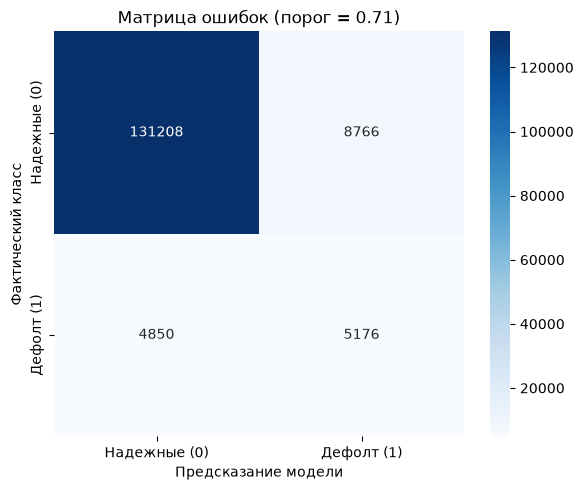

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Надежные (0)', 'Дефолт (1)'],
    yticklabels=['Надежные (0)', 'Дефолт (1)']
)
plt.title(f'Матрица ошибок (порог = {best_threshold:.2f})')
plt.xlabel('Предсказание модели')
plt.ylabel('Фактический класс')
plt.tight_layout()
plt.show()

1. **Оптимальный порог отсечения:**
   * Порог, максимизирующий $F_1$-score для класса дефолта, составил **0.7111** (максимальный $F_1 = 0.4319$).
   * Сдвиг порога с 0.5 до 0.71 закономерен: при обучении использовался параметр `class_weight='balanced'`, который искусственно завышает выдаваемые вероятности дефолта в сторону минорного класса, поэтому для баланса точности и полноты граница отсечения смещается выше.

2. **Структура ошибок классификации (на 150 000 клиентах):**
   * **True Positive (5 176):** успешно выявлено более половины всех реальных дефолтов (**Recall = 51.63%**).
   * **False Positive (8 766):** ложные тревоги составили лишь 6.26% от всех надежных заёмщиков (отказ получили клиенты, которые вернули бы долг). При этом в пуле заблокированных заявок каждый третий клиент — реальный неплательщик (**Precision = 37.13%**).
   * **False Negative (4 850):** дефолтные клиенты, которых модель не смогла распознать на этапе baseline из-за ограничений линейного разделения.

3. **Итоги блокнота `02_baseline.ipynb`:**
   * Зафиксированы контрольные метрики проекта:
     * **Наивный baseline:** ROC-AUC = **0.7905**, PR-AUC = **0.3068**.
     * **Baseline с очисткой по EDA:** ROC-AUC = **0.8557** (+0.0651), PR-AUC = **0.3743** (+0.0675), $F_1$ = **0.4319**.
   * Оба эксперимента залогированы в Weights & Biases.
   * Полученный вектор OOF-предсказаний сохранен в `data/processed/oof_predictions_baseline.csv` и будет использоваться как контрольная точка для сравнения с древесными моделями и ансамблями.